<a href="https://colab.research.google.com/github/davijsf/inteligencia-artificial/blob/main/perceptron/lista_perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# ***Exercício 01***

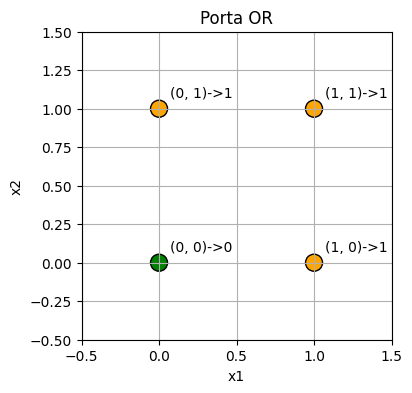

erros por época: [2, 2, 1, 0]
pesos finais: [1. 1.] bias final: -1.0
Convergiu na época 3 (0-indexado), ou seja, na 4° época rodada.


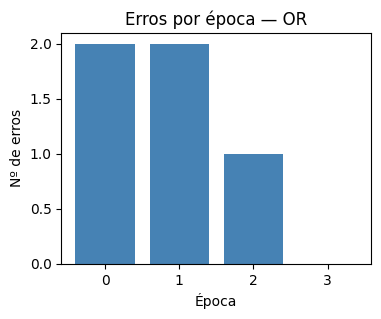

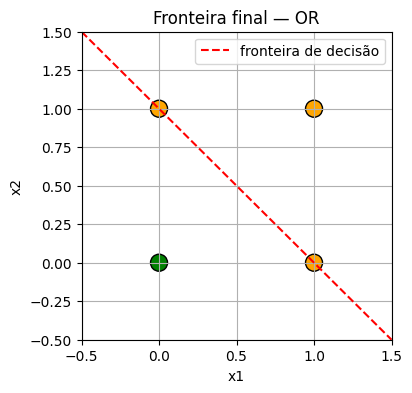

In [9]:
# Exercício 01
# 1
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y_or = np.array([0,1,1,1], dtype=float)

def plota_pontos(X, y, titulo):
  cores = np.where(y == 0, 'green', 'orange')
  plt.figure(figsize=(4,4))
  plt.scatter(X[:,0], X[:,1], c=cores, s=150, edgecolor='k')

  for (x1, x2), yi in zip(X, y):
    plt.annotate(f'({int(x1)}, {int(x2)})->{int(yi)}', (x1,x2),
    textcoords="offset points", xytext=(8,8))

  plt.xlabel('x1'); plt.ylabel('x2'); plt.title(titulo)
  plt.xlim(-0.5,1.5); plt.ylim(-0.5,1.5); plt.grid(True)
  plt.show()

plota_pontos(X, y_or, "Porta OR")

# 2
def treina_perceptron(X, y, alpha=1.0, max_epocas=50):
  n_amostras, n_features = X.shape
  w = np.zeros(n_features)
  b = 0.0
  erros = []
  for epoca in range(max_epocas):
    erros_epoca = 0
    for i in range(n_amostras):
      z = np.dot(w, X[i]) + b
      y_pred = 1.0 if z >= 0 else 0.0
      if y[i] != y_pred:
        w = w + alpha * (y[i] - y_pred) * X[i]
        b = b + alpha * (y[i] - y_pred)
        erros_epoca += 1
    erros.append(erros_epoca)
    if erros_epoca == 0:
      break
  return w, b, erros

# 3
w, b, erros = treina_perceptron(X, y_or)
print("erros por época:", erros)
print("pesos finais:", w, "bias final:", b)

epoca_convergencia = erros.index(0)
print(f"Convergiu na época {epoca_convergencia} (0-indexado), "
f"ou seja, na {epoca_convergencia+1}° época rodada.")



# 4
plt.figure(figsize=(4,3))
plt.bar(range(len(erros)), erros, color='steelblue')
plt.xlabel('Época'); plt.ylabel('Nº de erros')
plt.title('Erros por época — OR')
plt.show()

plt.figure(figsize=(4,4))
cores = np.where(y_or == 0, 'green', 'orange')
plt.scatter(X[:,0], X[:,1], c=cores, s=150, edgecolor='k')
x1_linha = np.linspace(-0.5, 1.5, 100)
if w[1] != 0:
    x2_linha = -(w[0]*x1_linha + b) / w[1]
    plt.plot(x1_linha, x2_linha, 'r--', label='fronteira de decisão')
plt.xlim(-0.5,1.5); plt.ylim(-0.5,1.5)
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(); plt.grid(True)
plt.title('Fronteira final — OR')
plt.show()

# ***Exercício 2***


In [12]:
# Exercício 02
y_and = np.array([0,0,0,1], dtype=float)
w, b, erros = treina_perceptron(X, y_and)

print("erros por época:", erros)

epoca_convergencia = erros.index(0)
print(f"Convergiu na época {epoca_convergencia} (0-indexado), "
f"ou seja, na {epoca_convergencia+1}° época rodada.")

print("pesos finais:", w, "bias final:", b)

erros por época: [2, 3, 3, 2, 1, 0]
Convergiu na época 5 (0-indexado), ou seja, na 6° época rodada.
pesos finais: [2. 1.] bias final: -3.0


**Comparação com a OR** (que convergiu na época 3, com `[2, 2, 1, 0]`): o AND precisou de **mais épocas**(6 contra 4). Olhando para os pontos, a diferença é a posição da classe minoritária: na OR só o ponto `(0,0)` é classe 0 (todo o resto é 1), e ele já está "isolado" perto da origem, fácil de cortar fora com pouco ajuste do bias. Na AND é o contrário - só `(1,1)` é classe 1, e os outros três pontos(incluindo a origem) são classe 0 - então a reta inicial (que passa pela origem com w = 0), começa classificando tudo como uma coisa só, do "lado errado" para três dos quatro pontos, e o Perceptron precisa de mais correções sucessivas (a lista chega a ter 3 erros na época 1) até empurrar a fronteira para perto do canto `(1,1)`. Ou seja: quanto mais "difícil" é isolar a classe minoritária a partir do ponto de partida w = (0,0), b = 0, mais atualizações (e épocas) são necessárias.

# ***Exercício 3***

In [16]:
y_xor = np.array([0,1,1,0], dtype=float)
w, b, erros = treina_perceptron(X, y_xor, alpha=1.0, max_epocas=50)

print("erros por época:", erros)

if 0 in erros:
  epoca_convergencia = erros.index(0)
  print(f"Convergiu na época {epoca_convergencia} (0-indexado), "
  f"ou seja, na {epoca_convergencia+1}° época rodada.")

else:
  print("NÂO convergiu em nenhuma das", len(erros), "épocas rodadas.")

# acurácia final, mesmo sem convergência
z = X.dot(w) + b
pred = (z >= 0).astype(float)
print("Predição final:", pred, " y_xor:", y_xor)
print("Acurácia final:", np.mean(pred == y_xor))

erros por época: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
NÂO convergiu em nenhuma das 50 épocas rodadas.
Predição final: [1. 1. 0. 0.]  y_xor: [0. 1. 1. 0.]
Acurácia final: 0.5


O erro **nunca vai a zero**: ele cai de 3 para 4 já na época 2 e trava em 4erros por época indefinidamente. O Perceptron não converge - a acurácia final fica em 50%, ou seja, no nível de "chutar aleatoriamente".

# ***Exercício 4***


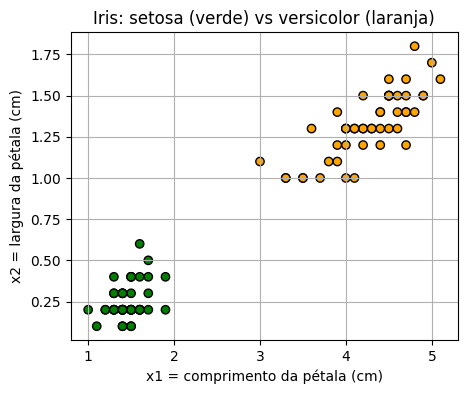

In [21]:
from sklearn.datasets import load_iris
iris = load_iris()

Xb = iris.data[(iris.target==0) | (iris.target==1)][:, [2,3]]
yb = (iris.target[(iris.target==0) | (iris.target==1)] ==
1).astype(float)

w, b, erros = treina_perceptron(Xb, yb, alpha=1.0, max_epocas=50)

cores = np.where(yb ==0, 'green', 'orange')
plt.figure(figsize=(5,4))
plt.scatter(Xb[:,0], Xb[:,1], c=cores, edgecolor='k')
plt.xlabel('x1 = comprimento da pétala (cm)')
plt.ylabel('x2 = largura da pétala (cm)')
plt.title('Iris: setosa (verde) vs versicolor (laranja)')
plt.grid(True)
plt.show()


Sim, dá para "chutar" a olho uma reta que separa os dois grupos perfeitamente - logo, são lineramente separáveis.

In [22]:
# 2
w, b, erros = treina_perceptron(Xb, yb, alpha=1.0, max_epocas=50)
print("Erros por época:", erros)

if 0 in erros:
    epoca_convergencia = erros.index(0)
    print(f"Convergiu na época {epoca_convergencia} (0-indexado), "
          f"ou seja, na {epoca_convergencia+1}ª época rodada.")
else:
    print("Não convergiu em", len(erros), "épocas.")

z = Xb.dot(w) + b
pred = (z >= 0).astype(float)
acuracia = np.mean(pred == yb)
print("w final:", w, " b final:", b)
print("acurácia final:", acuracia)


Erros por época: [2, 2, 0]
Convergiu na época 2 (0-indexado), ou seja, na 3ª época rodada.
w final: [0.5 0.8]  b final: -2.0
acurácia final: 1.0


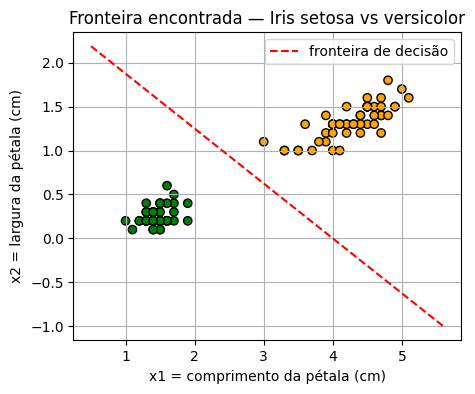

In [23]:
# 3
plt.figure(figsize=(5,4))
cores = np.where(yb == 0, 'green', 'orange')
plt.scatter(Xb[:,0], Xb[:,1], c=cores, edgecolor='k')

x1_linha = np.linspace(Xb[:,0].min()-0.5, Xb[:,0].max()+0.5, 100)
x2_linha = -(w[0]*x1_linha + b) / w[1]
plt.plot(x1_linha, x2_linha, 'r--', label='fronteira de decisão')

plt.xlabel('x1 = comprimento da pétala (cm)')
plt.ylabel('x2 = largura da pétala (cm)')
plt.title('Fronteira encontrada — Iris setosa vs versicolor')
plt.legend()
plt.grid(True)
plt.show()

OR (4 épocas) e AND (6 épocas) convergem porque suas classes cabem de um lado ou outro de uma reta, necessitando poucas correções a partir de w = 0, b = 0
w=0,b=0. A Iris setosa/versicolor converge ainda mais rápido (3 épocas) e com acurácia 100%, mostrando que mesmo dados reais e contínuos podem ser linearmente separáveis quando as classes são bem distintas nas features executadas. Já o XOR nunca converge (trava em 3–4 erros por época indefinidamente) porque suas classes formam uma configuração em "cruz" que nenhuma reta consegue separar — violando a premissa do Teorema de Rosenblatt. Essa comparação mostra que o Perceptron simples só é útil quando existe alguma fronteira linear que resolve o problema; ele não tem como "aprender" uma solução que não existe no espaço de retas. É exatamente essa limitação que motiva as redes multicamada (MLP): ao empilhar camadas com ativações não-lineares, a rede passa a compor várias retas em fronteiras curvas, resolvendo casos como o XOR onde um único Perceptron fracassa por definição, não por falta de treino.